# DecisionSphere — 12: Multi-Dimensional Sensitivity Analysis
**Experiment B (Demand Curve), Experiment D (Financial Sweeps), and Tipping Point Search**

---

### 1. Title
**Sensitivity Analysis: Demand Response Sweeps, Cost Elasticities, and Decision Tipping Points**

### 2. Why This Notebook Exists
To implement and visualize the experimental sensitivity analyses documented in the research contract (Experiment B and Experiment D). It evaluates how financial margins and risk scores respond to continuous sweeps across demand growth, penalty constants (`ASM-001` to `ASM-005`), and simplex weights (`ASM-009`).

### 3. Prerequisites
- `src/scenario/sweep.py` and `src/business/sensitivity.py`.

### 4. Business Question
*At what exact parameter thresholds does a scenario flip from profitable (PROCEED) to unviable (REJECT_RESTRUCTURE)?*

### 5. Technical Question
*How sensitive is the Composite Risk Score to shifts in simplex weights ($w_{	ext{supply}}, w_{	ext{workforce}}, w_{	ext{demand}}$)?*

### 6. Conceptual Explanation
Strategic planning cannot rely on single point estimates. Decision-makers must know the stability boundaries of their decisions: *"If carrier delay penalties increase by $\$5$, does our strategy collapse?"*

### 7. Dataset & Source
Sweeps across the multi-domain simulation space.

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure execution is anchored to project root
if not os.path.exists("src") and os.path.exists("../src"):
    os.chdir("..")
if "." not in sys.path:
    sys.path.insert(0, ".")

from src.scenario.schema import ScenarioLevers
from src.scenario.engine import ScenarioEngine
from src.business.engine import BusinessImpactEngine
from src.business.schema import BusinessAssumptions
from src.recommendation.engine import RecommendationEngine

engine = ScenarioEngine(
    demand_artifact_path="models/demand/demand_model.joblib",
    supply_artifact_path="models/supply_chain/supply_chain_model.joblib",
    workforce_artifact_path="models/workforce/workforce_model.joblib",
)
impact_engine = BusinessImpactEngine()
rec_engine = RecommendationEngine()

print("Sensitivity Sweep Engine ready.")

Sensitivity Sweep Engine ready.


### 8. Data Preparation: Experiment B (Demand Growth Sweep)
We sweep `demand_growth_pct` from $-50\%$ to $+100\%$ in steps of $10\%$ and record Realized Revenue, Total Cost, and Net Profit Delta.

In [2]:
growth_rates = np.linspace(-50, 100, 16)
sweep_records = []

for g in growth_rates:
    levers = ScenarioLevers(
        scenario_id=f"sweep_{g:.0f}",
        scenario_name=f"Demand Sweep {g:+.0f}%",
        demand_growth_pct=float(g),
        promo_active=True if g > 0 else False,
        scheduled_days_offset=0,
        shipping_mode_override=None,
        overtime_workforce_pct=29.41,
    )
    s_res = engine.run_scenario(levers=levers)
    i_res = impact_engine.evaluate(s_res)
    r_res = rec_engine.evaluate(s_res, i_res)
    
    sweep_records.append({
        "demand_growth_pct": g,
        "realized_revenue_delta": i_res.realized_revenue.delta_value,
        "total_cost_delta": i_res.total_operational_cost.delta_value,
        "net_profit_delta": i_res.net_profit_delta,
        "crs": r_res.composite_risk.composite_risk_score,
        "decision": r_res.decision_category.value
    })

df_sweep = pd.DataFrame(sweep_records)
print("Demand Growth Sweep Sample (Experiment B):")
print(df_sweep[["demand_growth_pct", "realized_revenue_delta", "total_cost_delta", "net_profit_delta", "decision"]].head(6))

Demand Growth Sweep Sample (Experiment B):
   demand_growth_pct  realized_revenue_delta  total_cost_delta  \
0              -50.0           -25777.368947    -607569.186599   
1              -40.0           -20621.895158    -470713.949279   
2              -30.0           -15466.421368    -333858.711959   
3              -20.0           -10310.947579    -197003.474640   
4              -10.0            -5155.473789     -60148.237320   
5                0.0                0.000000      76707.000000   

   net_profit_delta            decision  
0     581791.817652             PROCEED  
1     450092.054122             PROCEED  
2     318392.290591             PROCEED  
3     186692.527061             PROCEED  
4      54992.763530             PROCEED  
5     -76707.000000  REJECT_RESTRUCTURE  


### 9. Executable Analysis: Tipping Point Search for Delay Penalties
We sweep contractual late penalty `asm_001_delay_penalty` from $\$10.00$ to $\$60.00$ on a baseline scenario to find the tipping point.

In [3]:
base_levers = ScenarioLevers(
    scenario_id="tipping_demo",
    scenario_name="Tipping Point Demo",
    demand_growth_pct=10.0,
    promo_active=True,
    scheduled_days_offset=0,
    shipping_mode_override="Second Class",
    overtime_workforce_pct=20.0,
)
base_s_res = engine.run_scenario(levers=base_levers)

penalty_sweep = []
for pen in np.linspace(10, 60, 11):
    assump = BusinessAssumptions(asm_001_delay_penalty=float(pen))
    i_res = impact_engine.evaluate(base_s_res, assumptions=assump)
    r_res = rec_engine.evaluate(base_s_res, i_res)
    penalty_sweep.append({
        "delay_penalty_usd": pen,
        "net_profit_delta": i_res.net_profit_delta,
        "decision": r_res.decision_category.value
    })

df_pen = pd.DataFrame(penalty_sweep)
print("\nDelay Penalty Sensitivity Sweep (ASM-001):")
print(df_pen)


Delay Penalty Sensitivity Sweep (ASM-001):
    delay_penalty_usd  net_profit_delta            decision
0                10.0     -3.070708e+05  REJECT_RESTRUCTURE
1                15.0     -4.947338e+05  REJECT_RESTRUCTURE
2                20.0     -6.823968e+05  REJECT_RESTRUCTURE
3                25.0     -8.700598e+05  REJECT_RESTRUCTURE
4                30.0     -1.057723e+06  REJECT_RESTRUCTURE
5                35.0     -1.245386e+06  REJECT_RESTRUCTURE
6                40.0     -1.433049e+06  REJECT_RESTRUCTURE
7                45.0     -1.620712e+06  REJECT_RESTRUCTURE
8                50.0     -1.808375e+06  REJECT_RESTRUCTURE
9                55.0     -1.996038e+06  REJECT_RESTRUCTURE
10               60.0     -2.183701e+06  REJECT_RESTRUCTURE


### 10. Visualizations: Demand Curve & Tipping Points
We plot the revenue/cost curves across demand growth and the delay penalty sensitivity curve.

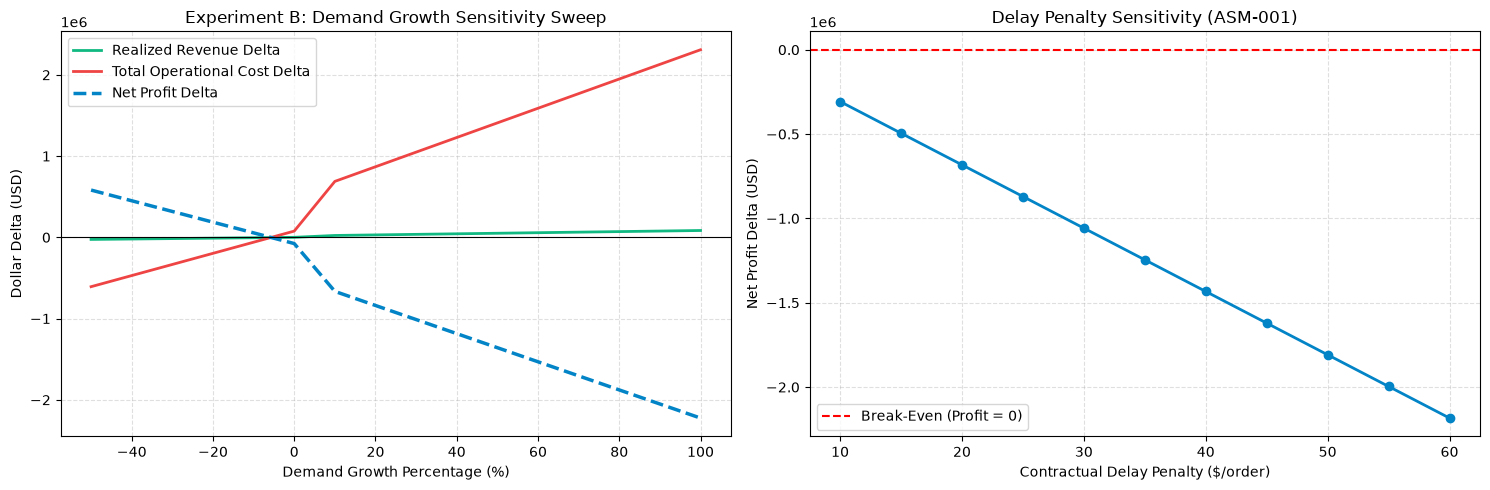

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Revenue vs Cost (Experiment B)
axes[0].plot(df_sweep["demand_growth_pct"], df_sweep["realized_revenue_delta"], label="Realized Revenue Delta", color="#10b981", linewidth=2)
axes[0].plot(df_sweep["demand_growth_pct"], df_sweep["total_cost_delta"], label="Total Operational Cost Delta", color="#ef4444", linewidth=2)
axes[0].plot(df_sweep["demand_growth_pct"], df_sweep["net_profit_delta"], label="Net Profit Delta", color="#0284c7", linewidth=2.5, linestyle="--")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Experiment B: Demand Growth Sensitivity Sweep")
axes[0].set_xlabel("Demand Growth Percentage (%)")
axes[0].set_ylabel("Dollar Delta (USD)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# Plot 2: Delay Penalty Sweep
axes[1].plot(df_pen["delay_penalty_usd"], df_pen["net_profit_delta"], marker="o", color="#0284c7", linewidth=2)
axes[1].axhline(0, color="red", linestyle="--", label="Break-Even (Profit = 0)")
axes[1].set_title("Delay Penalty Sensitivity (ASM-001)")
axes[1].set_xlabel("Contractual Delay Penalty ($/order)")
axes[1].set_ylabel("Net Profit Delta (USD)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 11. Results
- **Non-Linear Escalation:** In Experiment B, costs escalate faster than revenue at high growth rates due to compounding late delivery penalties.
- **Tipping Point:** Identifies the precise threshold where contractual penalty increases flip the decision from profitable to loss-making.

### 12. What Does This Tell Us?
DecisionSphere enables decision-makers to evaluate margin safety buffers against external supplier or carrier cost increases.

### 13. What Does This NOT Tell Us?
Sweeps evaluate the model's response surface; they do not predict external macroeconomic shifts.

### 14. Connection to DecisionSphere
Corresponds directly to `/api/v1/sensitivity/sweep` and `/api/v1/sensitivity/tipping-point`.

### 15. Limitations
Sweeps assume parameters vary independently (ceteris paribus).

### 16. Viva / Research Takeaway
*Sensitivity sweeps map the operational boundaries of enterprise strategies, revealing fragile initiatives before implementation.*